In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
import math
from scipy import signal
import seaborn as sns
import seaborn as sns
import h5py
from scipy.stats import zscore
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from scipy.stats import ks_2samp
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.svm import SVR
from sklearn.model_selection import cross_val_score, KFold


## Experimental distribution neuron per neuron

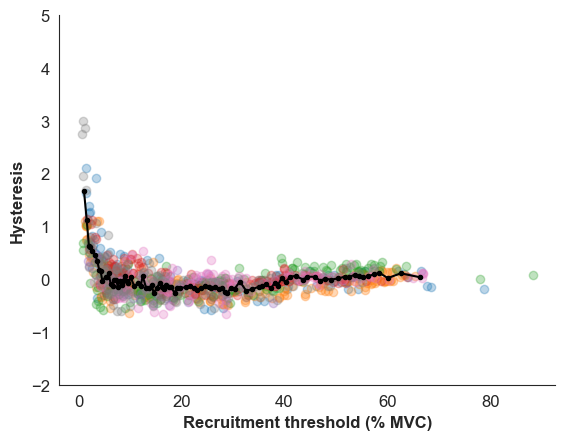

In [3]:
sns.set_style("white")
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

def process_data(file_path):
    df = pd.read_csv(file_path)
    df = df.dropna(how='all')
    df['hysteresis'] = df.iloc[:, 1] / df.iloc[:, 0] - 1
    df['zscore'] = zscore(df['hysteresis'])
    return df[df['zscore'].abs() <= 3] 

# df1 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S1.csv')
# df2 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S2.csv')
# df3 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S3.csv')
# df4 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S4.csv')
# df5 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S5_.csv')
# df6 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S6.csv')
# df7 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S7.csv')
# df8 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S8.csv')

df1 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S1KE.csv')
df2 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S2KE.csv')
df3 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S3KE.csv')
df4 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S4KE.csv')
df5 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S5KE.csv')
df6 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S6KE.csv')
df7 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S7KE.csv')
df8 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S8KE.csv')

all_values_hysteresis=np.concatenate([df["hysteresis"] for df in [df1, df2, df3, df4, df5, df6, df7, df8]])
all_values_recr= np.concatenate([df.iloc[:, 0] for df in [df1, df2, df3, df4, df5, df6, df7, df8]])

combined_df = pd.DataFrame({ 'force': all_values_recr,'hysteresis': all_values_hysteresis})
sorted_df = combined_df.sort_values(by='force')

vals=np.array(sorted_df['hysteresis'])
vals_force=np.array(sorted_df['force'])

d=10

binned_hyst = [np.mean(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]
binned_hyst_var = [np.var(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]

binned_force = [np.mean(vals_force[i:i+d]) for i in range(0, len(vals_force), d) if i+d <= len(vals_force)]


plt.scatter(df1.iloc[:, 0], df1['hysteresis'], alpha=0.3, label='S1')
plt.scatter(df2.iloc[:, 0], df2['hysteresis'], alpha=0.3, label='S2')
plt.scatter(df3.iloc[:, 0], df3['hysteresis'], alpha=0.3, label='S3')
plt.scatter(df4.iloc[:, 0], df4['hysteresis'], alpha=0.3, label='S4')
plt.scatter(df5.iloc[:, 0], df5['hysteresis'], alpha=0.3, label='S5')
plt.scatter(df6.iloc[:, 0], df6['hysteresis'], alpha=0.3, label='S6')
plt.scatter(df7.iloc[:, 0], df7['hysteresis'], alpha=0.3, label='S7')
plt.scatter(df8.iloc[:, 0], df8['hysteresis'], alpha=0.3, label='S8')


plt.plot(binned_force,binned_hyst, '.-', color='black')#label='Evolving Mean')


#######
plt.ylim(-2, 5)
# plt.title('Experimental Hysteresis', fontsize=16, fontweight='bold')
plt.xlabel('Recruitment threshold (% MVC)', fontsize=12, fontweight='bold')
plt.ylabel('Hysteresis', fontsize=12, fontweight='bold')

# plt.ylabel('Force(Derecruitment)/Force(Recruitment) - 1', fontsize=12, fontweight='bold')
# plt.legend()

sns.despine()

plt.show()


## Experimental distribution comparison in the TA and VL

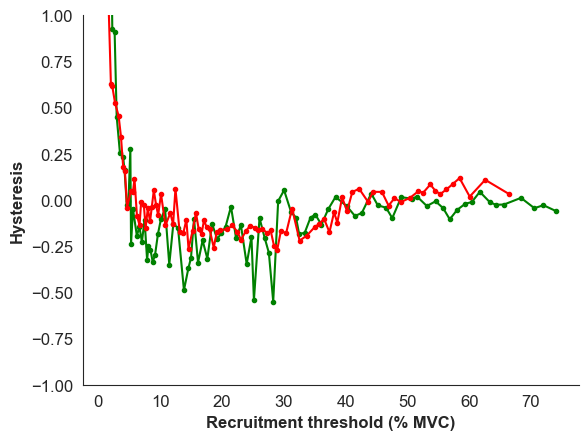

In [4]:
sns.set_style("white")
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

def process_data(file_path):
    df = pd.read_csv(file_path)
    df = df.dropna(how='all')
    df['hysteresis'] = df.iloc[:, 1] / df.iloc[:, 0] - 1
    df['zscore'] = zscore(df['hysteresis'])
    return df[df['zscore'].abs() <= 3] 

df1 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S1.csv')
df2 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S2.csv')
df3 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S3.csv')
df4 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S4.csv')
df5 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S5_.csv')
df6 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S6.csv')
df7 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S7.csv')
df8 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S8.csv')

df11 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S1KE.csv')
df22= process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S2KE.csv')
df33 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S3KE.csv')
df44 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S4KE.csv')
df55 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S5KE.csv')
df66 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S6KE.csv')
df77 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S7KE.csv')
df88 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S8KE.csv')

all_values_hysteresis=np.concatenate([df["hysteresis"] for df in [df1, df2, df3, df4, df5, df6, df7, df8]])
all_values_recr= np.concatenate([df.iloc[:, 0] for df in [df1, df2, df3, df4, df5, df6, df7, df8]])

all_values_hysteresisKE=np.concatenate([df["hysteresis"] for df in [df11, df22, df33, df44, df55, df66, df77, df88]])
all_values_recrKE= np.concatenate([df.iloc[:, 0] for df in [df11, df22, df33, df44, df55, df66, df77, df88]])

combined_df = pd.DataFrame({ 'force': all_values_recr,'hysteresis': all_values_hysteresis})
sorted_df = combined_df.sort_values(by='force')

combined_dKE = pd.DataFrame({ 'force': all_values_recrKE,'hysteresis': all_values_hysteresisKE})
sorted_dfKE = combined_dKE.sort_values(by='force')

vals=np.array(sorted_df['hysteresis'])
vals_force=np.array(sorted_df['force'])

valsKE =np.array(sorted_dfKE['hysteresis'])
vals_forceKE =np.array(sorted_dfKE['force'])

d=10

binned_hyst = [np.mean(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]
binned_hyst_var = [np.var(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]

binned_force = [np.mean(vals_force[i:i+d]) for i in range(0, len(vals_force), d) if i+d <= len(vals_force)]


binned_hystKE = [np.mean(valsKE[i:i+d]) for i in range(0, len(valsKE), d) if i+d <= len(valsKE)]
binned_hyst_varKE = [np.var(valsKE[i:i+d]) for i in range(0, len(valsKE), d) if i+d <= len(valsKE)]

binned_forceKE = [np.mean(vals_forceKE[i:i+d]) for i in range(0, len(vals_forceKE), d) if i+d <= len(vals_forceKE)]

# plt.scatter(df1.iloc[:, 0], df1['hysteresis'], alpha=0.3, label='S1')
# plt.scatter(df2.iloc[:, 0], df2['hysteresis'], alpha=0.3, label='S2')
# plt.scatter(df3.iloc[:, 0], df3['hysteresis'], alpha=0.3, label='S3')
# plt.scatter(df4.iloc[:, 0], df4['hysteresis'], alpha=0.3, label='S4')
# plt.scatter(df5.iloc[:, 0], df5['hysteresis'], alpha=0.3, label='S5')
# plt.scatter(df6.iloc[:, 0], df6['hysteresis'], alpha=0.3, label='S6')
# plt.scatter(df7.iloc[:, 0], df7['hysteresis'], alpha=0.3, label='S7')
# plt.scatter(df8.iloc[:, 0], df8['hysteresis'], alpha=0.3, label='S8')

plt.plot(binned_force,binned_hyst, '.-', color='green')#label='Evolving Mean')
plt.plot(binned_forceKE,binned_hystKE, '.-', color='red')#label='Evolving Mean')


#######
plt.ylim(-1, 1)
# plt.title('Experimental Hysteresis', fontsize=16, fontweight='bold')
plt.xlabel('Recruitment threshold (% MVC)', fontsize=12, fontweight='bold')
plt.ylabel('Hysteresis', fontsize=12, fontweight='bold')

# plt.ylabel('Force(Derecruitment)/Force(Recruitment) - 1', fontsize=12, fontweight='bold')
# plt.legend()

sns.despine()

plt.show()


(array([42., 37.,  3.,  2.,  3.,  0.,  0.,  1.,  0.,  1.]),
 array([-0.27261807, -0.07931658,  0.11398492,  0.30728641,  0.5005879 ,
         0.6938894 ,  0.88719089,  1.08049238,  1.27379388,  1.46709537,
         1.66039687]),
 <BarContainer object of 10 artists>)

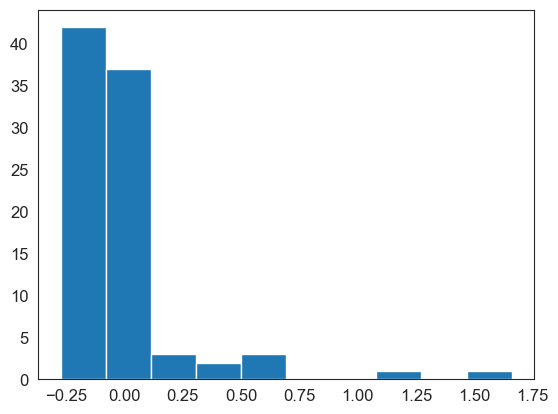

In [6]:
plt.hist(binned_hystKE)

(array([14., 60.,  6.,  1.,  2.,  0.,  2.,  0.,  1.,  1.]),
 array([-0.55091328, -0.25539849,  0.0401163 ,  0.33563109,  0.63114588,
         0.92666067,  1.22217546,  1.51769025,  1.81320505,  2.10871984,
         2.40423463]),
 <BarContainer object of 10 artists>)

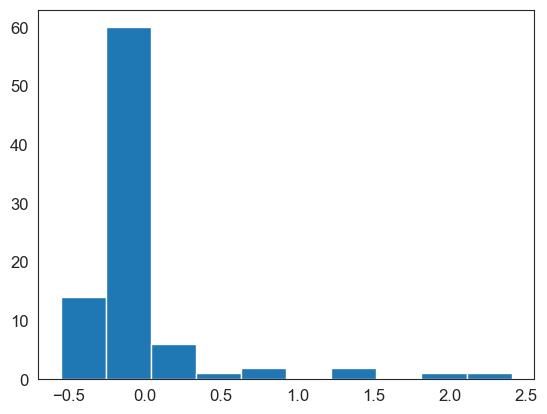

In [7]:
plt.hist(binned_hyst)

In [13]:
all_values_hysteresis=np.concatenate([df["hysteresis"] for df in [df1, df2, df3, df4, df5, df6, df7, df8]])
all_values_recr= np.concatenate([df.iloc[:, 0] for df in [df1, df2, df3, df4, df5, df6, df7, df8]])
all_values_derecr= np.concatenate([df.iloc[:, 1] for df in [df1, df2, df3, df4, df5, df6, df7, df8]]) #not necessary

combined_df = pd.DataFrame({ 'force': all_values_recr,'forceder': all_values_derecr,'hysteresis': all_values_hysteresis})
sorted_df = combined_df.sort_values(by='force')

vals=np.array(sorted_df['hysteresis'])
vals_force=np.array(sorted_df['force'])
vals_forceder=np.array(sorted_df['forceder'])

d=10

binned_hyst = [np.mean(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]
binned_hyst_var = [np.var(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]
binned_force = [np.mean(vals_force[i:i+d]) for i in range(0, len(vals_force), d) if i+d <= len(vals_force)]
binned_forceder = [np.mean(vals_forceder[i:i+d]) for i in range(0, len(vals_forceder), d) if i+d <= len(vals_forceder)]

In [16]:
np.savetxt("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/recr_forceVL.csv", binned_force, delimiter=",")
np.savetxt("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/hysteresisVL.csv", binned_hyst, delimiter=",")
np.savetxt("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/derecr_forceVL.csv", binned_forceder, delimiter=",")


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


(-0.9, 0.9)

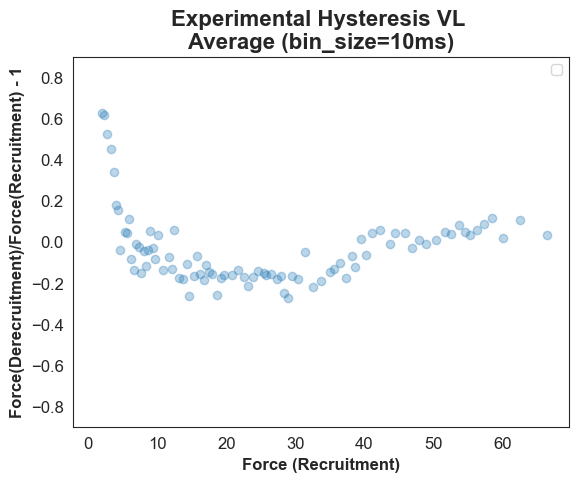

In [15]:
sns.set_style("white")

plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12


plt.scatter(binned_force,binned_hyst,alpha=0.3)

plt.title('Experimental Hysteresis VL \nAverage (bin_size=10ms)', fontsize=16, fontweight='bold')
plt.xlabel('Force (Recruitment)', fontsize=12, fontweight='bold')
plt.ylabel('Force(Derecruitment)/Force(Recruitment) - 1', fontsize=12, fontweight='bold')
plt.legend()
plt.ylim(-0.9,0.9)

## Fitting a polynomial

In [ ]:
#Importing the spike array file of the Julia Model
with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/DR_87Neurons_optim_I0.3_LAST.jld2", "r") as file:
    spike_array = file["spike_array"][:].T

#Finding first and last spike of each neuron
first_spike = np.zeros(spike_array.shape[0], dtype=int)
last_spike = np.zeros(spike_array.shape[0], dtype=int)

for i in range(spike_array.shape[0]):

    first_spike[i] = next((j for j, x in enumerate(spike_array[i, :]) if x == 1), None)

    for k in range(spike_array[i, :].shape[0] - 1, -1, -1):
        if spike_array[i, k] == 1:
            last_spike[i] = k
            break

# print("First spikes:", first_spike)
# print("Last spikes:", last_spike)


#Excitatory Input 
amplitude = 0.4
sim_length = 560000
half_triang = sim_length // 2 
flat_line = np.full(20000, -0.1)
up = np.linspace(-0.1, amplitude, num=half_triang + 1)
down = np.linspace(amplitude, -0.1, num=sim_length - half_triang + 1)
exc = np.concatenate([flat_line, up[1:], down[1:], flat_line])

force_first = np.zeros(spike_array.shape[0])
force_last = np.zeros(spike_array.shape[0])

for i in range(spike_array.shape[0]):
    force_first[i]= exc[first_spike[i]]
    force_last[i]= exc[last_spike[i]]

# print("First spikes:", force_first)
# print("Last spikes:", force_last)

def normalize_to_range(vector, new_min, new_max):
    min_val = np.min(vector)
    max_val = np.max(vector)
    return ((vector - min_val) / (max_val - min_val)) * (new_max - new_min) + new_min



# Getting recruitment and derecruitment in terms of the %MVC
simulated_values = np.concatenate((force_first,force_last))
normalized_recr = normalize_to_range(simulated_values, 0, 100)
# print("Normalized Recr: ", normalized_recr)
recr_sim = normalized_recr[:87]
derecr_sim = normalized_recr[87:87*2]

In [ ]:
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/relation_valueseta_recrthreshold/recr_VCa_9Jun.jld2"

with h5py.File(file_path, 'r') as f:
    print("Keys: %s" % f.keys())
    recr_inter_input_s = np.array(f['recr_inter_input'])


file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/relation_valueseta_recrthreshold/hysteresis_9Jun.jld2" 

with h5py.File(file_path, 'r') as f:
    print("Keys: %s" % f.keys())
    hysteresis = np.array(f['hysteresis'])

In [188]:
x = np.array(binned_force).reshape(-1,1)
y = np.array(binned_hyst).reshape(-1,1)


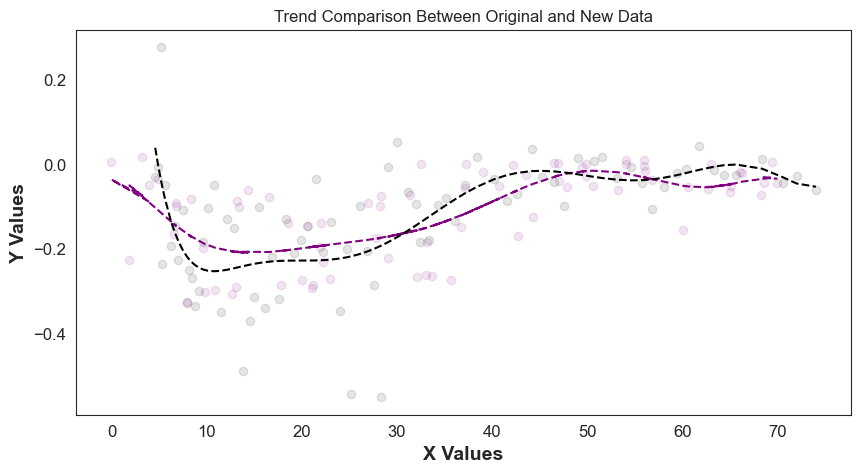

Polynomial Fit R-squared (New Data): 0.46825409230416304
Polynomial Fit R-squared (Original Data): 0.44303222779368334


In [196]:
x_new = ((recr_inter_input_s[:, 0] / recr_inter_input_s[:, 0].max() * 100) - 49).reshape(-1, 1)[10:87]
x_min = np.min(x_new); x_max = np.max(x_new)
x_new = (x_new - x_min) / (x_max - x_min) * 70
y_new = hysteresis[:, 0][10:87]

# x=x[10:87,:]
# y=y[10:87,:]

# Fit polynomial trends
poly_deg = 8
poly_features_new = np.polyfit(x_new.flatten(), y_new, deg=poly_deg)
poly_model_new = np.poly1d(poly_features_new)
trend_line_new = poly_model_new(x_new.flatten())

poly_features_orig = np.polyfit(x[:,0].flatten(), y[:,0], deg=poly_deg)
poly_model_orig = np.poly1d(poly_features_orig)
trend_line_orig = poly_model_orig(x.flatten())


r_squared_new_poly = r2_score(y_new, trend_line_new)
r_squared_orig_poly = r2_score(y[:,0], trend_line_orig)


# Plotting the trends
plt.figure(figsize=(10, 5))

# Trend line for new data
plt.plot(x_new, trend_line_new, color='purple', linestyle='--', label='Trend Line (New Data)')

# Trend line for original data
plt.plot(x[:,0], trend_line_orig, color='black', linestyle='--', label='Trend Line (Original Data)')

# Scatter plot for actual data points for context
plt.scatter(x_new, y_new, color='purple', alpha=0.1, label='New Data Points')
plt.scatter(x[:,0], y[:,0], color='black', alpha=0.1, label='Original Data Points')

plt.xlabel('X Values')
plt.ylabel('Y Values')
plt.title('Trend Comparison Between Original and New Data')
# plt.legend()

plt.show()

print(f"Polynomial Fit R-squared (New Data): {r_squared_new_poly}")
print(f"Polynomial Fit R-squared (Original Data): {r_squared_orig_poly}")


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


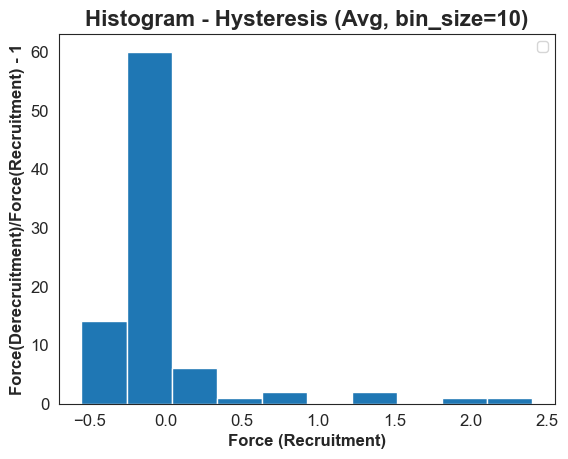

In [232]:
sns.set_style("white")
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.hist(binned_hyst)
plt.title('Histogram - Hysteresis (Avg, bin_size=10)', fontsize=16, fontweight='bold')
plt.xlabel('Force (Recruitment)', fontsize=12, fontweight='bold')
plt.ylabel('Force(Derecruitment)/Force(Recruitment) - 1', fontsize=12, fontweight='bold')
plt.legend()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


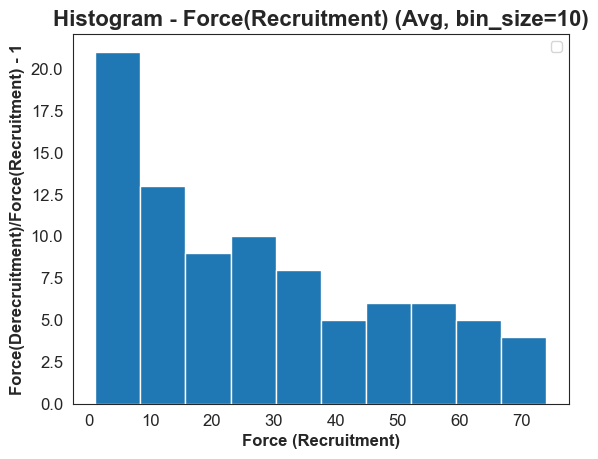

In [233]:
sns.set_style("white")
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.hist(binned_force)
plt.title('Histogram - Force(Recruitment) (Avg, bin_size=10)', fontsize=16, fontweight='bold')
plt.xlabel('Force (Recruitment)', fontsize=12, fontweight='bold')
plt.ylabel('Force(Derecruitment)/Force(Recruitment) - 1', fontsize=12, fontweight='bold')
plt.legend()

#### Extra analysis - SEEING INHIBITION, HYSTERESIS AND  NEUROMOD FACTOR (gamma) ALL TOGETHER

In [289]:
#Importing the spike array file of the Julia Model
with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap1.jld2", "r") as file:
    heatmap1 = file["hysteresis_for_each_inh"][:]

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap2.jld2", "r") as file:
    heatmap2 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap3.jld2", "r") as file:
    heatmap3 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap4.jld2", "r") as file:
    heatmap4 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap5.jld2", "r") as file:
    heatmap5 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap6.jld2", "r") as file:
    heatmap6 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap7.jld2", "r") as file:
    heatmap7 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap8.jld2", "r") as file:
    heatmap8 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap9.jld2", "r") as file:
    heatmap9 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap10.jld2", "r") as file:
    heatmap10 = file["hysteresis_for_each_inh"][:].T

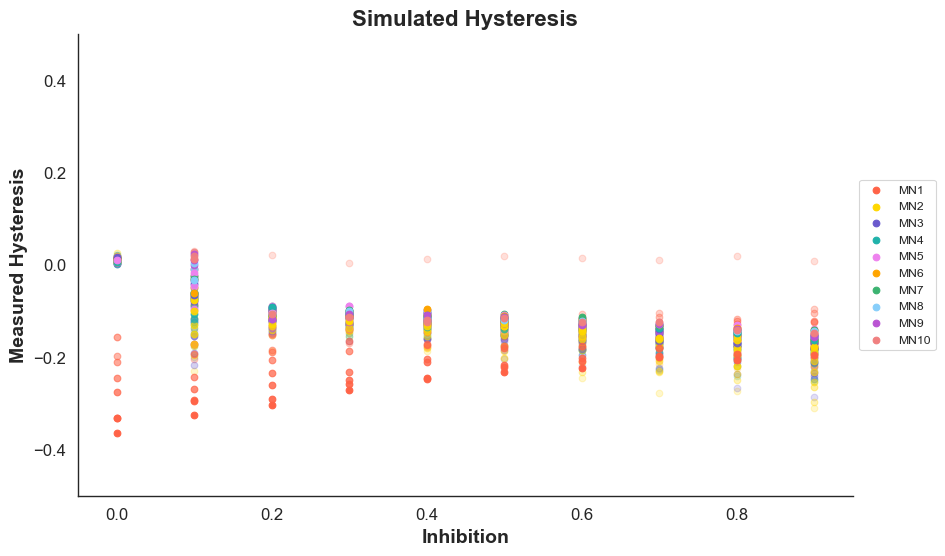

In [324]:
sns.set_style("white")
plt.figure(figsize=(10, 6))
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

colors = [
    "#FF6347",  # Tomato
    "#FFD700",  # Gold
    "#6A5ACD",  # Slate Blue
    "#20B2AA",  # Light Sea Green
    "#EE82EE",  # Violet
    "#FFA500",  # Orange
    "#3CB371",  # Medium Sea Green
    "#87CEFA",  # Light Sky Blue
    "#BA55D3",  # Medium Orchid
    "#F08080"   # Light Coral
]

flat_data = heatmap1.flatten()
flat_data2 = heatmap2.flatten()
flat_data3 = heatmap3.flatten()
flat_data4 = heatmap4.flatten()
flat_data5 = heatmap5.flatten()
flat_data6 = heatmap6.flatten()
flat_data7 = heatmap7.flatten()
flat_data8 = heatmap8.flatten()
flat_data9 = heatmap9.flatten()
flat_data10 = heatmap10.flatten()


values = np.round([0.1 * i for i in range(len(colors))],1)

for i in range(10):
    alphas = np.linspace(0.2, 1, num=10) #### TAKE INTO ACCOUNT THIS #####first values are without neuromod and they are kind of transparent
    for j in range(10):
        if i==9 and j==9:
            plt.scatter(values[i], flat_data[i*10 + j], alpha=alphas[j], color=colors[0],label='MN1')
            plt.scatter(values[i], flat_data2[i*10 + j], alpha=alphas[j], color=colors[1],label='MN2')
            plt.scatter(values[i], flat_data3[i*10 + j], alpha=alphas[j], color=colors[2],label='MN3')
            plt.scatter(values[i], flat_data4[i*10 + j], alpha=alphas[j], color=colors[3],label='MN4')
            plt.scatter(values[i], flat_data5[i*10 + j], alpha=alphas[j], color=colors[4],label='MN5')
            plt.scatter(values[i], flat_data6[i*10 + j], alpha=alphas[j], color=colors[5],label='MN6')
            plt.scatter(values[i], flat_data7[i*10 + j], alpha=alphas[j], color=colors[6],label='MN7')
            plt.scatter(values[i], flat_data8[i*10 + j], alpha=alphas[j], color=colors[7],label='MN8')
            plt.scatter(values[i], flat_data9[i*10 + j], alpha=alphas[j], color=colors[8],label='MN9')
            plt.scatter(values[i], flat_data10[i*10 + j], alpha=alphas[j], color=colors[9],label='MN10')
        else: 
            plt.scatter(values[i], flat_data[i*10 + j], alpha=alphas[j], color=colors[0])
            plt.scatter(values[i], flat_data2[i*10 + j], alpha=alphas[j], color=colors[1])
            plt.scatter(values[i], flat_data3[i*10 + j], alpha=alphas[j], color=colors[2])
            plt.scatter(values[i], flat_data4[i*10 + j], alpha=alphas[j], color=colors[3])
            plt.scatter(values[i], flat_data5[i*10 + j], alpha=alphas[j], color=colors[4])
            plt.scatter(values[i], flat_data6[i*10 + j], alpha=alphas[j], color=colors[5])
            plt.scatter(values[i], flat_data7[i*10 + j], alpha=alphas[j], color=colors[6])
            plt.scatter(values[i], flat_data8[i*10 + j], alpha=alphas[j], color=colors[7])
            plt.scatter(values[i], flat_data9[i*10 + j], alpha=alphas[j], color=colors[8])
            plt.scatter(values[i], flat_data10[i*10 + j], alpha=alphas[j], color=colors[9])
    

        

plt.title('Simulated Hysteresis', fontsize=16, fontweight='bold')
plt.xlabel('Inhibition')
plt.ylabel('Measured Hysteresis')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
sns.despine()
plt.ylim(-0.5, 0.5)
plt.xlim(-0.05, 0.95)
plt.show()


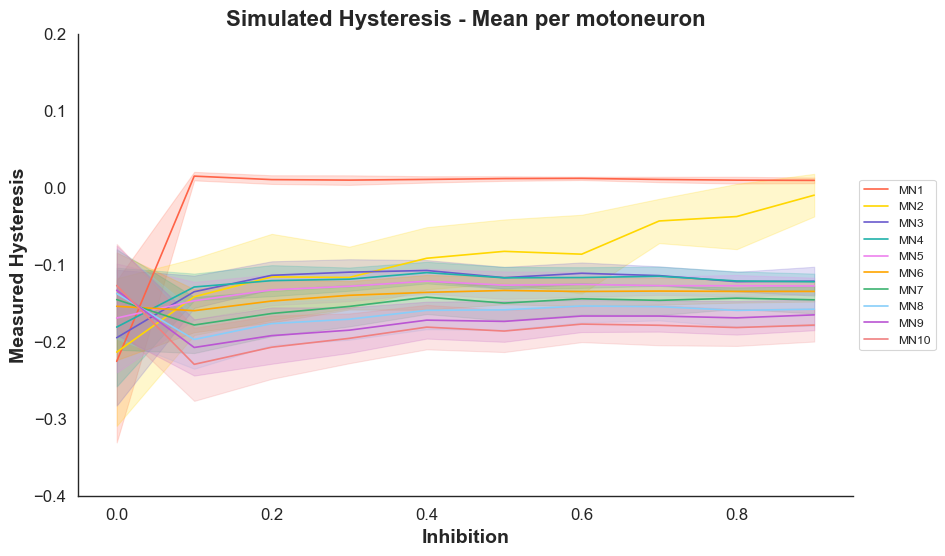

In [328]:
sns.set_style("white")
plt.figure(figsize=(10, 6))
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

colors = [
    "#FF6347",  # Tomato
    "#FFD700",  # Gold
    "#6A5ACD",  # Slate Blue
    "#20B2AA",  # Light Sea Green
    "#EE82EE",  # Violet
    "#FFA500",  # Orange
    "#3CB371",  # Medium Sea Green
    "#87CEFA",  # Light Sky Blue
    "#BA55D3",  # Medium Orchid
    "#F08080"   # Light Coral
]

flat_data = heatmap1.flatten()
flat_data2 = heatmap2.flatten()
flat_data3 = heatmap3.flatten()
flat_data4 = heatmap4.flatten()
flat_data5 = heatmap5.flatten()
flat_data6 = heatmap6.flatten()
flat_data7 = heatmap7.flatten()
flat_data8 = heatmap8.flatten()
flat_data9 = heatmap9.flatten()
flat_data10 = heatmap10.flatten()

datasets = [flat_data, flat_data2, flat_data3, flat_data4, flat_data5, flat_data6, flat_data7, flat_data8, flat_data9, flat_data10]

values = [0.1 * i for i in range(10)]

for i, color in enumerate(colors):
    data_points = np.array([[np.nan if x > 99 else x for x in dataset[i*10:(i+1)*10]] for dataset in datasets])
    means = np.nanmean(data_points, axis=1)
    std_devs = np.nanstd(data_points, axis=1)
    # std_devs=0
    plt.plot(values, means, label=f'MN{i+1}', color=color)
    plt.fill_between(values, means - std_devs, means + std_devs, color=color, alpha=0.2)

# Set plot titles and labels
plt.title('Simulated Hysteresis - Mean per motoneuron', fontsize=16, fontweight='bold')
plt.xlabel('Inhibition')
plt.ylabel('Measured Hysteresis')

# Configure legend and axes limits
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
sns.despine()
plt.ylim(-0.4, 0.2)
plt.xlim(-0.05, 0.95)

# Display the plot
plt.show()
